# Attack, Defence and League Points: A Step-by-Step Analysis
## 2025/26 English Premier League
**Research question:** How are attacking and defensive performance associated with league points?

This notebook supports an English preliminary project proposal. Run cells from top to bottom using **Shift + Enter**. Keep the two original CSV files in the same folder as this notebook. Raw CSV files are never modified.

**Workflow:** prepare libraries → import CSV files → inspect → clean → aggregate → merge → analyse → visualise → interpret.

**Source documentation still required:** add the original download URL and collection date for each dataset before submission. File names alone do not establish provenance.

## Step 1 — Prepare the libraries
- **Pandas:** read, inspect and organise tables.
- **NumPy:** numerical calculations.
- **Matplotlib:** charts.

Anaconda may already contain these libraries. If the next cell raises `ModuleNotFoundError`, run `%pip install pandas numpy matplotlib` in a new code cell, restart the kernel if requested, and try again. Installing a library and importing it are different steps.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Import the two original CSV files
`read_csv()` loads a file into a DataFrame: a table with rows and columns. We keep raw tables and clean copies separately.

In [2]:
players_raw = pd.read_csv("players_data-2025_2026.csv")
matches_raw = pd.read_csv("season-2526.csv")
players = players_raw.copy()
matches = matches_raw.copy()
print("Player data shape:", players.shape)
print("Match data shape:", matches.shape)

Player data shape: (2839, 102)
Match data shape: (380, 22)


### Step 3a — Preview the data
`head()` shows the first five rows. Each player row describes a player-team record; each match row describes one match. Preview selected player columns to keep the table readable.

In [3]:
display(players[["Player", "Squad", "Comp", "Pos", "MP", "Gls", "Ast"]].head())
display(matches.head())

,Player,Squad,Comp,Pos,MP,Gls,Ast
0,Brenden Aaronson,Leeds United,eng Premier League,"MF,FW",37,4,5
1,Jerome Abbey,Wolves,eng Premier League,MF,1,0,0
2,Zach Abbott,Nottingham Forest,eng Premier League,DF,3,0,0
3,Jones El-Abdellaoui,Celta Vigo,es La Liga,"MF,FW",22,2,0
4,Himad Abdelli,Marseille,fr Ligue 1,MF,8,0,0


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,19,10,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,3,16,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,10,7,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,10,12,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,16,14,6,4,14,8,6,5,0,0,0,0


### Step 3b — Inspect columns and data types
`info()` reports non-missing counts and data types. The complete column list helps identify which variables are available.

In [4]:
print("Player columns:", players.columns.tolist())
players[["Player", "Squad", "Comp", "Pos", "Saves", "SoTA", "GA"]].info()
matches.info()
print("Leagues in player data:")
print(players["Comp"].value_counts())

Player columns: ['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP'

### Step 3c — Check missing values and duplicate records
Missing goalkeeper values for outfield players are expected. Do not replace these with an average or zero. We check duplicates using identifiers, not only entire rows.

In [5]:
missing = players.isna().sum()
print("Missing player values (columns with missing entries):")
print(missing[missing > 0].to_string())
print("Missing match values:", matches.isna().sum().sum())
print("Duplicate matches:", matches.duplicated(["Date", "HomeTeam", "AwayTeam"]).sum())
print("Duplicate player-team records:", players.duplicated(["Player", "Squad"]).sum())

Missing player values (columns with missing entries):
Nation                          3
Age                             2
Born                            2
Rk_stats_keeper              2645
Nation_stats_keeper          2645
Pos_stats_keeper             2645
Comp_stats_keeper            2645
Age_stats_keeper             2645
Born_stats_keeper            2645
MP_stats_keeper              2645
Starts_stats_keeper          2645
Min_stats_keeper             2645
90s_stats_keeper             2645
GA                           2645
GA90                         2645
SoTA                         2645
Saves                        2645
Save%                        2649
W                            2645
D                            2645
L                            2645
CS                           2645
CS%                          2651
PKatt_stats_keeper           2645
PKA                          2645
PKsv                         2645
PKm                          2645
Nation_stats_shooting       

## Step 4 — Clean and filter
Convert dates and relevant numbers explicitly. Stop on invalid values rather than silently creating missing data. Select the English Premier League and standardise team names before merging.

In [6]:
matches["Date"] = pd.to_datetime(matches["Date"], errors="raise")
for column in ["FTHG", "FTAG", "HS", "AS", "HST", "AST"]:
    matches[column] = pd.to_numeric(matches[column], errors="raise")
for column in ["Saves", "SoTA", "GA"]:
    players[column] = pd.to_numeric(players[column], errors="raise")
print("Date range:", matches.Date.min().date(), "to", matches.Date.max().date())

Date range: 2025-08-15 to 2026-05-24


In [7]:
name_map = {'Manchester City':'Man City','Manchester Utd':'Man United','Newcastle United':'Newcastle','Nottingham Forest':"Nott'm Forest",'Tottenham Hotspur':'Tottenham','West Ham United':'West Ham','Leeds United':'Leeds'}
epl = players.loc[players.Comp.eq('eng Premier League')].copy()
epl['Team'] = epl.Squad.replace(name_map)
teams = set(matches.HomeTeam) | set(matches.AwayTeam)
assert set(epl.Team) == teams, 'Team coverage mismatch'
assert not matches.duplicated(['Date','HomeTeam','AwayTeam']).any()
assert not epl.duplicated(['Player','Squad']).any()
assert matches[['FTHG','FTAG','HS','AS','HST','AST']].notna().all().all()
print('Matched teams:', len(teams), '| EPL player records:', len(epl))
print('Duplicate match and player-team keys: none')

Matched teams: 20 | EPL player records: 551
Duplicate match and player-team keys: none


### Step 4b — Validate the selected goalkeeper records
Only goalkeeper rows are used for goalkeeper metrics. Selected values must be complete and non-negative. Missing values elsewhere are retained because they are not used in this analysis.

In [8]:
keepers = epl.loc[epl.Pos.str.contains("GK", na=False)].copy()
assert keepers[["Saves", "SoTA", "GA"]].notna().all().all()
assert (keepers[["Saves", "SoTA", "GA"]] >= 0).all().all()
assert (keepers.Saves <= keepers.SoTA).all()
expected_results = np.select([matches.FTHG > matches.FTAG, matches.FTHG == matches.FTAG], ["H", "D"], default="A")
assert (matches.FTR == expected_results).all()
print("Goalkeeper records:", len(keepers))
print("Goalkeeper values and match-result codes passed the checks.")

Goalkeeper records: 40
Goalkeeper values and match-result codes passed the checks.


## Step 5 — Convert matches into team-match records
Each match contributes one home-team row and one away-team row. This makes it possible to aggregate all games for a team. GF means goals scored; GA means goals conceded. Award 3 points for a win, 1 for a draw and 0 for a loss.

In [9]:
home = matches[['HomeTeam','FTHG','FTAG','HS','HST','AST']].copy()
away = matches[['AwayTeam','FTAG','FTHG','AS','AST','HST']].copy()
cols = ['Team','GF','GA','Shots','ShotsOnTarget','ShotsOnTargetAgainst']
home.columns = away.columns = cols
long = pd.concat([home,away], ignore_index=True)
long['Points'] = np.select([long.GF > long.GA,long.GF == long.GA],[3,1],default=0)

print("Team-match rows:", len(long))
display(long.head())

Team-match rows: 760


,Team,GF,GA,Shots,ShotsOnTarget,ShotsOnTargetAgainst,Points
0,Liverpool,4,2,19,10,3,3
1,Aston Villa,0,0,3,3,3,1
2,Brighton,1,1,10,4,2,1
3,Sunderland,3,0,10,5,4,3
4,Tottenham,3,0,16,6,4,3


## Step 6 — Calculate team-level indicators
Sum match values for each team, then divide by games played to calculate per-match rates. Shot accuracy is shots on target divided by all shots. Points are derived from match results and do not incorporate administrative deductions.

In [10]:
summary = long.groupby('Team')[cols[1:]+['Points']].sum()
summary['Played'] = long.groupby('Team').size()
assert summary.Played.eq(38).all()
for raw,new in [('GF','GoalsPerMatch'),('GA','ConcededPerMatch'),('Shots','ShotsPerMatch'),('ShotsOnTargetAgainst','OppSOTPerMatch')]:
    summary[new] = summary[raw] / summary.Played
summary['ShotAccuracy'] = summary.ShotsOnTarget / summary.Shots

display(summary[["Played", "Points", "GF", "GA", "GoalsPerMatch", "ConcededPerMatch"]].round(3))

,Played,Points,GF,GA,GoalsPerMatch,ConcededPerMatch
Team,,,,,,
Arsenal,38,85,71,27,1.868,0.711
Aston Villa,38,65,56,49,1.474,1.289
Bournemouth,38,57,58,54,1.526,1.421
Brentford,38,53,55,52,1.447,1.368
Brighton,38,53,52,46,1.368,1.211
Burnley,38,22,38,75,1.000,1.974
Chelsea,38,52,58,52,1.526,1.368
Crystal Palace,38,45,41,51,1.079,1.342
Everton,38,49,47,50,1.237,1.316


## Step 7 — Merge goalkeeper statistics and check consistency
Sum saves and shots faced across goalkeepers before calculating the team save rate. Team is the merge key. Compare overlapping measures across the two sources before relying on merged results.

In [11]:
keeper_totals = keepers.groupby("Team")[["Saves", "SoTA", "GA"]].sum(min_count=1)
keeper_totals = keeper_totals.rename(columns={"SoTA":"KeeperSoTA", "GA":"KeeperGA"})
summary = summary.join(keeper_totals, how="left", validate="one_to_one")
assert summary[["Saves", "KeeperSoTA", "KeeperGA"]].notna().all().all()
assert summary.KeeperSoTA.gt(0).all()
summary["SaveRate"] = summary.Saves / summary.KeeperSoTA
summary["SOTSourceDifference"] = summary.KeeperSoTA - summary.ShotsOnTargetAgainst
summary["GASourceDifference"] = summary.KeeperGA - summary.GA
summary = summary.sort_values("Points", ascending=False)
display(summary[["Points", "SaveRate", "SOTSourceDifference", "GASourceDifference"]].round(3))

,Points,SaveRate,SOTSourceDifference,GASourceDifference
Team,,,,
Arsenal,85,0.685,-1.0,0.0
Man City,78,0.718,-3.0,0.0
Man United,71,0.659,-3.0,0.0
Aston Villa,65,0.708,-7.0,0.0
Liverpool,60,0.669,-5.0,0.0
Bournemouth,57,0.694,-5.0,0.0
Sunderland,54,0.724,-4.0,0.0
Brentford,53,0.707,-12.0,0.0
Brighton,53,0.710,-3.0,0.0


**Data-quality finding:** All 20 teams have differences in shots-on-target counts between sources. Chelsea also has a two-goal difference in goalkeeper goals conceded. Definitions or coverage may differ; the reason has not been verified. Therefore, goalkeeper save rate is retained for inspection but excluded from the main conclusions and models until source documentation is checked.

## Step 8 — Analyse relationships
Pearson correlation measures linear association, from −1 to +1. A negative value means one variable tends to decrease as the other increases. Compare absolute magnitudes when assessing strength. These are same-season associations, not causal effects.

In [12]:
metrics = ["GoalsPerMatch", "ConcededPerMatch", "ShotsPerMatch", "ShotAccuracy", "OppSOTPerMatch"]
correlations = summary[metrics].corrwith(summary.Points).to_frame("Pearson correlation with points")
display(correlations.round(3))

,Pearson correlation with points
GoalsPerMatch,0.908
ConcededPerMatch,-0.900
ShotsPerMatch,0.810
ShotAccuracy,0.131
OppSOTPerMatch,-0.837


## Step 9 — Make one figure with two panels
Each point is one team. Both panels use the same points axis so the attacking and defensive patterns can be compared. The dashed lines are descriptive linear fits, not predictions of future results.

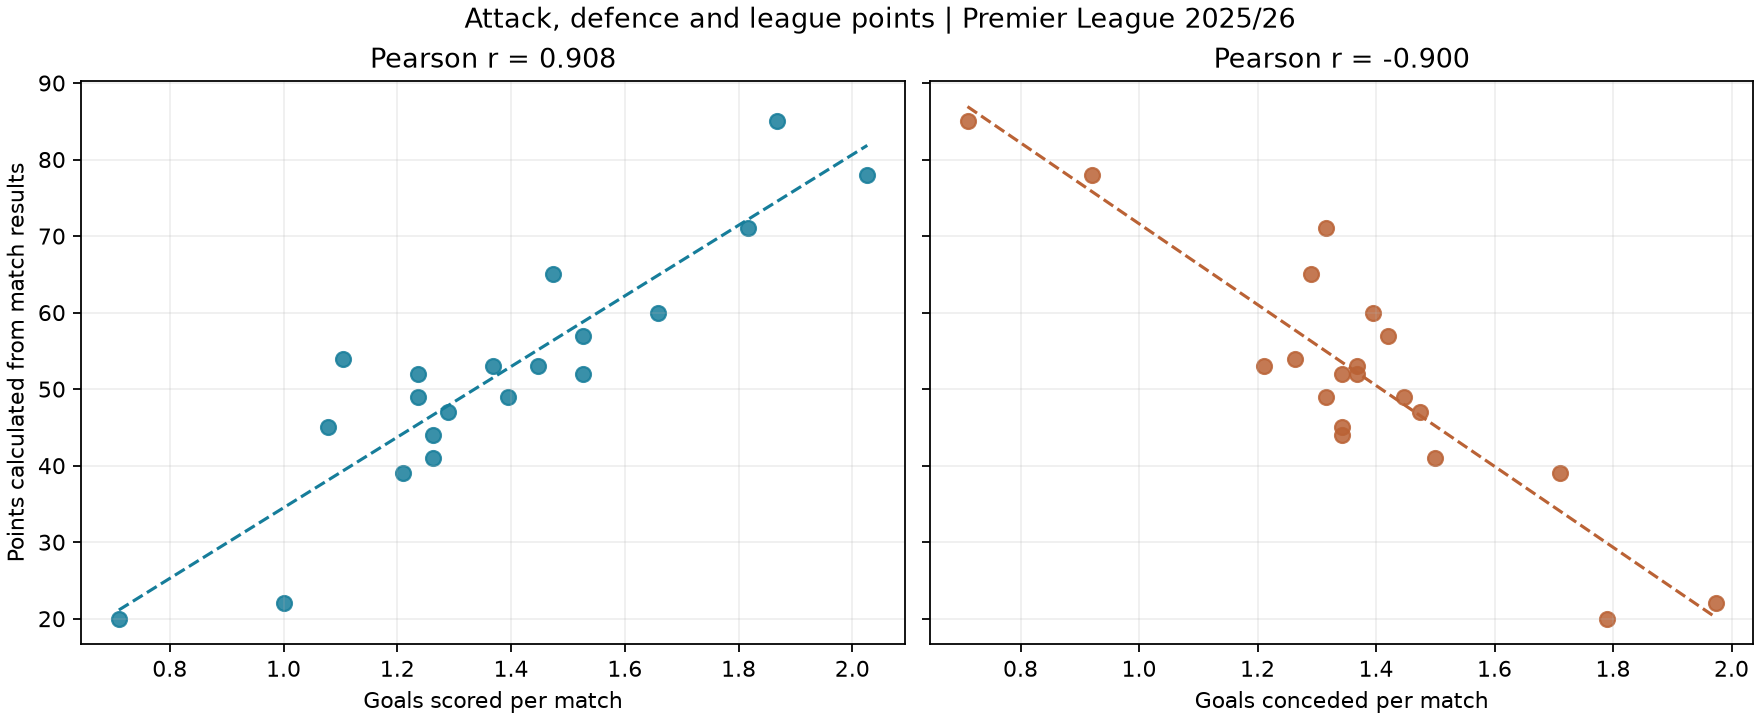

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, layout="constrained")
for ax, metric, label, colour in zip(
    axes, ["GoalsPerMatch", "ConcededPerMatch"],
    ["Goals scored per match", "Goals conceded per match"], ["#167d9a", "#ba6235"]):
    x = summary[metric]
    y = summary["Points"]
    ax.scatter(x, y, color=colour, s=45, alpha=0.85)
    slope, intercept = np.polyfit(x, y, 1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(grid, slope * grid + intercept, "--", color=colour, linewidth=1.4)
    ax.set_xlabel(label)
    ax.set_title(f"Pearson r = {x.corr(y):.3f}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Points calculated from match results")
fig.suptitle("Attack, defence and league points | Premier League 2025/26")
plt.show()

## Step 10 — Interpret the initial results
- Goals scored per match have a strong positive association with points (r ≈ 0.908).
- Goals conceded per match have a strong negative association with points (r ≈ −0.900).
- These magnitudes are close. This analysis does not establish that attack is more important than defence, or vice versa.
- Shot accuracy alone has a weak association with points (r ≈ 0.131); it should not be treated as a complete measure of attacking strength.

**Why this is preliminary:** Scores determine match points, so the first two relationships are partly inherent in the scoring system. There are only 20 teams and one season. The analysis supports a proposal, not a general causal conclusion.

## Step 11 — Prepare the English proposal
Use these verified steps and initial observations to describe the project title, purpose, data, tasks, planned visualisation, success criteria and applicable collaboration arrangement.

Before submission:
1. Add both original dataset links and collection dates.
2. Resolve or explain the cross-source discrepancies before extending goalkeeper analysis.
3. Confirm whether collaboration is allowed and document the correct arrangement.
4. Consider further seasons and a small validated model as future work; neither is claimed as completed here.

No extra CSV files are automatically exported by this notebook. Tables and the main chart are displayed inline. Save the notebook after running all cells.